In [1]:
%pip install -U huggingface_hub

Note: you may need to restart the kernel to use updated packages.


c:\Users\hartmawa\Music\Deep Learning\src\.venv\Scripts\python.exe: No module named pip


In [1]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="JackFurby/blackjack",
    repo_type="dataset",
    local_dir="./data/blackjack"
)

print("Downloaded to:", dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 40968 files:   0%|          | 0/40968 [00:00<?, ?it/s]

Downloaded to: C:\Users\hartmawa\Music\Deep Learning\src\Project\data\blackjack


In [2]:
from pathlib import Path

data_folder = Path(
    r"C:\Users\hartmawa\Music\Deep Learning\src\Project\data\blackjack"
)

print("Dataset exists:", data_folder.exists())
print("Training labels exist:",
      (data_folder / "splits/standard/train.json").exists())

Dataset exists: True
Training labels exist: True


Number of training hands: 14304
Sample annotation:
{'img_path': 'imgs/standard/train/0/0.png', 'class_label': 1, 'concept_label': [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0], 'player_card_points': [[[[172, 974], [50, 974], [172, 789], [50, 789]], 'AD'], [[[185, 789], [307, 789], [185, 973], [307, 973]], 'KS']], 'dealer_card_points': [[[[50, 50], [172, 50], [50, 235], [172, 235]], '7D']], 'game_number': 0}


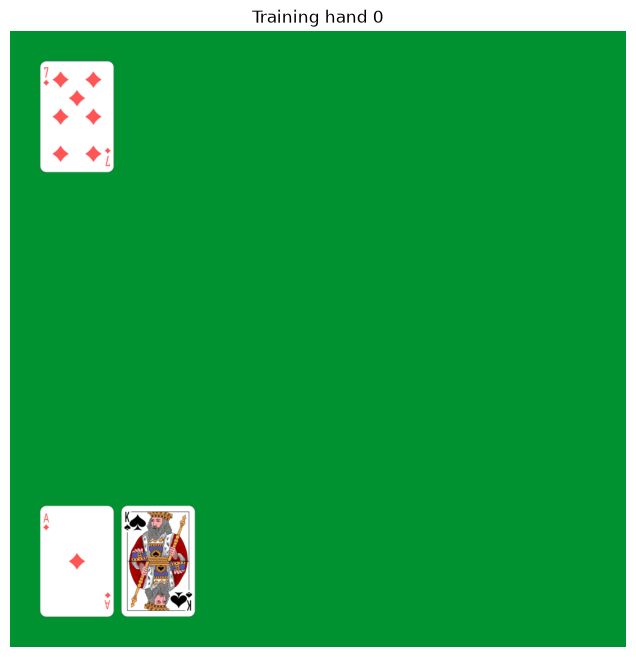

In [3]:
## Select training example

import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

data_folder = Path("./data/blackjack")

# Read the training annotations
with open(data_folder / "splits/standard/train.json", "r") as file:
    train_annotations = json.load(file)

print("Number of training hands:", len(train_annotations))

# Get the first hand
sample_id = next(iter(train_annotations))
sample = train_annotations[sample_id]

print("Sample annotation:")
print(sample)

# Open and display the full image
image = Image.open(data_folder / sample["img_path"]).convert("RGB")

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title(f"Training hand {sample_id}")
plt.axis("off")
plt.show()

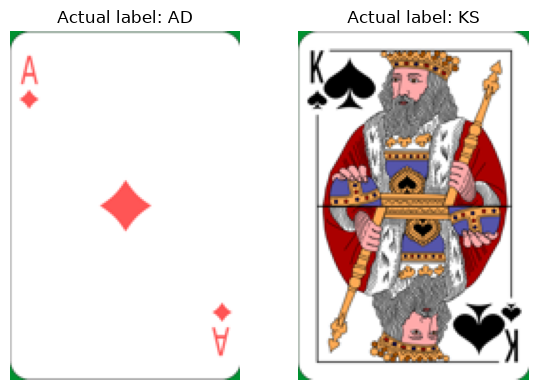

In [ ]:
## Crop Just Player Cards

player_cards = sample["player_card_points"]

fig, axes = plt.subplots(
    1, len(player_cards),
    figsize=(3 * len(player_cards), 4),
    squeeze=False
)

for ax, (corners, card_label) in zip(axes[0], player_cards):
    # Find the rectangle enclosing the four corners
    x_coordinates = [point[0] for point in corners]
    y_coordinates = [point[1] for point in corners]

    crop_box = (
        min(x_coordinates),
        min(y_coordinates),
        max(x_coordinates),
        max(y_coordinates)
    )

    card_image = image.crop(crop_box)

    ax.imshow(card_image)
    ax.set_title(f"Actual label: {card_label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
## Import ResNet-18

import json
import torch
from pathlib import Path
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

torch.manual_seed(42)

data_folder = Path("./data/blackjack")
ranks = ["A", "2", "3", "4", "5", "6", "7",
         "8", "9", "10", "J", "Q", "K"]

# Resize the entire card so its corner symbols stay visible.
# Normalize using the pretrained model's ImageNet settings.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class CardDataset(Dataset):
    def __init__(self, root, split, transform):
        self.root = root
        self.transform = transform
        self.cards = []

        with open(root / f"splits/standard/{split}.json") as f:
            annotations = json.load(f)

        for sample in annotations.values():
            for group in ["player_card_points", "dealer_card_points"]:
                for corners, card_label in sample[group]:
                    # "QS" -> "Q"; "10H" -> "10"
                    rank = card_label[:-1]

                    if rank not in ranks:
                        raise ValueError(f"Unexpected card: {card_label}")

                    xs = [point[0] for point in corners]
                    ys = [point[1] for point in corners]
                    box = (min(xs), min(ys), max(xs), max(ys))

                    self.cards.append((
                        sample["img_path"],
                        box,
                        ranks.index(rank)
                    ))

    def __len__(self):
        return len(self.cards)

    def __getitem__(self, index):
        image_path, box, label = self.cards[index]

        with Image.open(self.root / image_path) as image:
            card = image.convert("RGB").crop(box)

        return self.transform(card), label


train_dataset = CardDataset(data_folder, "train", transform)
val_dataset = CardDataset(data_folder, "val", transform)

# num_workers=0 keeps this simple for a Windows notebook.
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0
)

print("Training cards:", len(train_dataset))
print("Validation cards:", len(val_dataset))

Training cards: 60028
Validation cards: 25958
